# GRU — SoH Estimation

## Imports

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import os
import joblib
import copy

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

work_dir = os.getcwd()
print("work_dir:", work_dir)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device  :", DEVICE)

MODEL_NAME = "gru"

work_dir: /content
device  : cuda


## Data Loader

In [32]:
input_folder = os.path.join(work_dir, "data_normalized")

X_train = np.load(os.path.join(input_folder, "X_train.npy"))
y_train = np.load(os.path.join(input_folder, "y_train.npy"))
X_val = np.load(os.path.join(input_folder, "X_val.npy"))
y_val = np.load(os.path.join(input_folder, "y_val.npy"))
X_test = np.load(os.path.join(input_folder, "X_test.npy"))
y_test = np.load(os.path.join(input_folder, "y_test.npy"))

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print(f"y_train: [{y_train.min():.2f}, {y_train.max():.2f}]")


def create_loader(X, y, batch_size=128, shuffle=True):
    Xt = torch.tensor(X, dtype=torch.float32)
    yt = torch.tensor(y, dtype=torch.float32)
    return DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=shuffle)


train_loader = create_loader(X_train, y_train)
val_loader = create_loader(X_val, y_val, shuffle=False)
test_loader = create_loader(X_test, y_test, shuffle=False)


Train: (9163, 1166, 5) | Val: (1776, 1166, 5) | Test: (1744, 1166, 5)
y_train: [70.00, 97.65]


## Attention Module

In [33]:
class Attention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.attn = nn.Linear(hidden_size, hidden_size)
        self.v = nn.Linear(hidden_size, 1, bias=False)

    def forward(self, x):  # x: (B, T, H)
        score = self.v(torch.tanh(self.attn(x)))  # (B, T, 1)
        weight = torch.softmax(score, dim=1)  # (B, T, 1)
        return (weight * x).sum(dim=1)  # (B, H)


## Model

In [34]:
class GRUModel(nn.Module):
    def __init__(self, input_size=5):
        super().__init__()
        hidden_size = 120  # from Optuna
        num_layers = 3
        dropout = 0.02

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=False,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = Attention(hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)  # (B, T, hidden)
        ctx = self.attention(out)  # (B, hidden)
        return self.fc(self.dropout(ctx)).squeeze(-1)


GRU_MODEL_CLASS = GRUModel

model = GRUModel(X_train.shape[2]).to(DEVICE)
total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"GRU params: {total:,}")
print(f"Input size: {X_train.shape[2]}")


GRU params: 234,721
Input size: 5


## Config

In [35]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.HuberLoss(delta=1.5)  # robust to noisy boundary windows
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5, min_lr=1e-6
)
os.makedirs(os.path.join(work_dir, "model"), exist_ok=True)


## Training

In [36]:
EPOCHS = 100
PATIENCE = 20

train_losses, val_losses = [], []
best_val = float("inf")
best_state = copy.deepcopy(model.state_dict())
counter = 0

for epoch in range(1, EPOCHS + 1):
    # Train
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        batch_losses.append(loss.item())
    train_loss = np.mean(batch_losses)

    # Validate
    model.eval()
    batch_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            batch_losses.append(criterion(model(xb), yb).item())
    val_loss = np.mean(batch_losses)

    scheduler.step(val_loss)
    train_losses.append(np.sqrt(train_loss))
    val_losses.append(np.sqrt(val_loss))

    print(
        f"Ep {epoch:03d}/{EPOCHS} | train={np.sqrt(train_loss):.4f} | val={np.sqrt(val_loss):.4f}"
    )

    # Best-epoch checkpoint
    if val_loss < best_val:
        best_val = val_loss
        best_state = copy.deepcopy(model.state_dict())
        counter = 0
        torch.save(best_state, os.path.join(work_dir, "model", f"{'gru'}_best.pt"))
    else:
        counter += 1

    if counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print(f"\nTraining done. Best val loss: {best_val:.6f}")


Ep 001/100 | train=10.4657 | val=10.2099
Ep 002/100 | train=9.7423 | val=9.5301
Ep 003/100 | train=9.0347 | val=8.8076
Ep 004/100 | train=8.2708 | val=8.0243
Ep 005/100 | train=7.4308 | val=7.1581
Ep 006/100 | train=6.4881 | val=6.1731
Ep 007/100 | train=5.3842 | val=4.9990
Ep 008/100 | train=4.0188 | val=3.6034
Ep 009/100 | train=2.7467 | val=2.7033
Ep 010/100 | train=2.4298 | val=2.2804
Ep 011/100 | train=2.2192 | val=2.0596
Ep 012/100 | train=2.0612 | val=2.0503
Ep 013/100 | train=1.9672 | val=2.0397
Ep 014/100 | train=1.8569 | val=2.0066
Ep 015/100 | train=1.7949 | val=2.1158
Ep 016/100 | train=1.7138 | val=2.0335
Ep 017/100 | train=1.6713 | val=2.0634
Ep 018/100 | train=1.6493 | val=2.0972
Ep 019/100 | train=1.6239 | val=2.0891
Ep 020/100 | train=1.5934 | val=2.0207
Ep 021/100 | train=1.4764 | val=2.0122
Ep 022/100 | train=1.4612 | val=2.0445
Ep 023/100 | train=1.4525 | val=2.0419
Ep 024/100 | train=1.4051 | val=2.0059
Ep 025/100 | train=1.3193 | val=1.9659
Ep 026/100 | train=1.24

## Evaluate

In [37]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        preds.append(model(xb.to(DEVICE)).cpu().numpy())
y_pred = np.concatenate(preds)


## Metrics & Figures

RMSE : 2.8015 %
MAE  : 2.0067 %
R²   : 0.793669


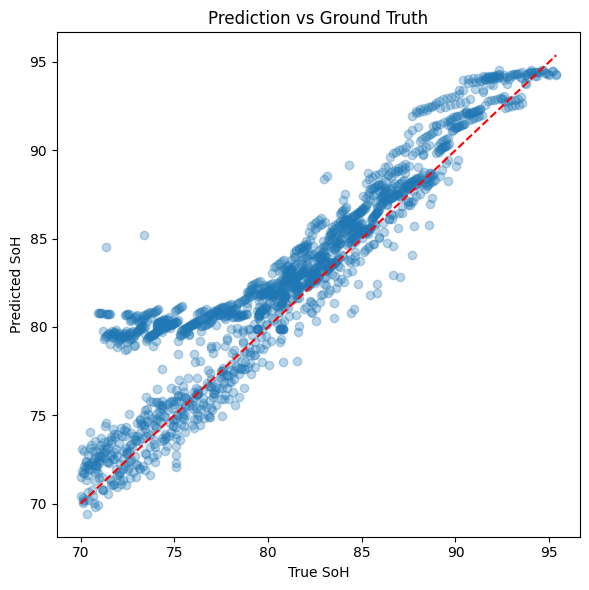

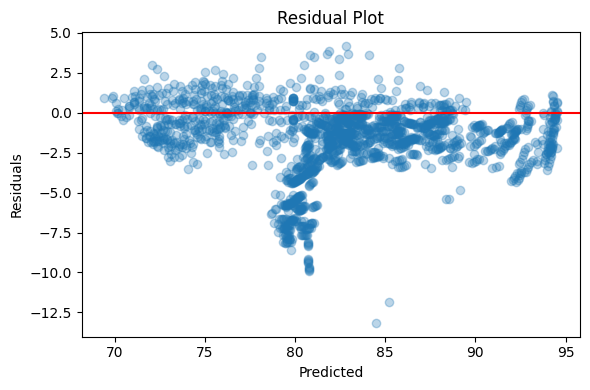

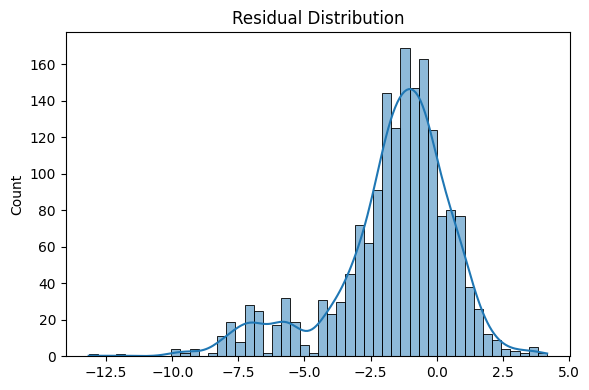

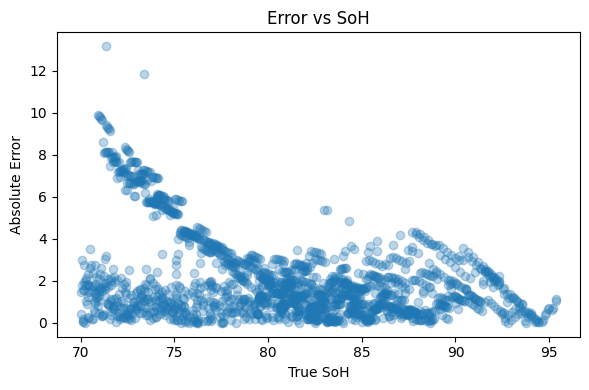

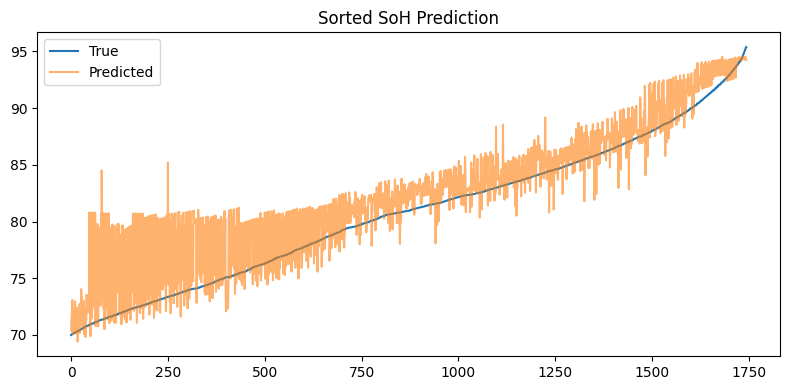

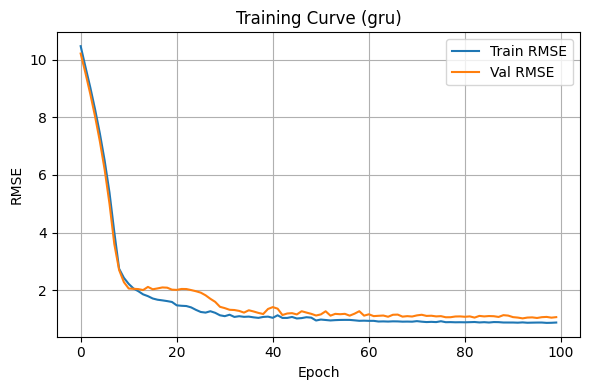

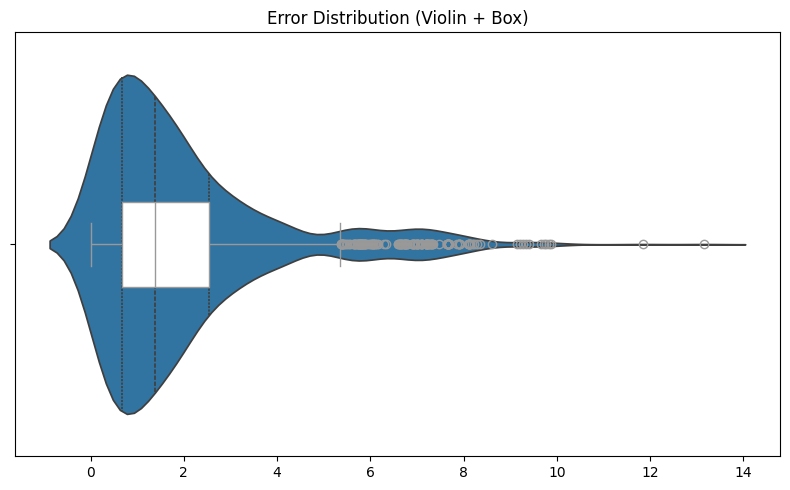

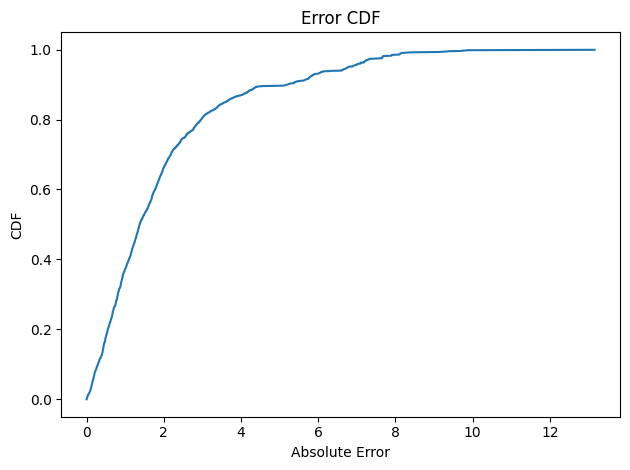

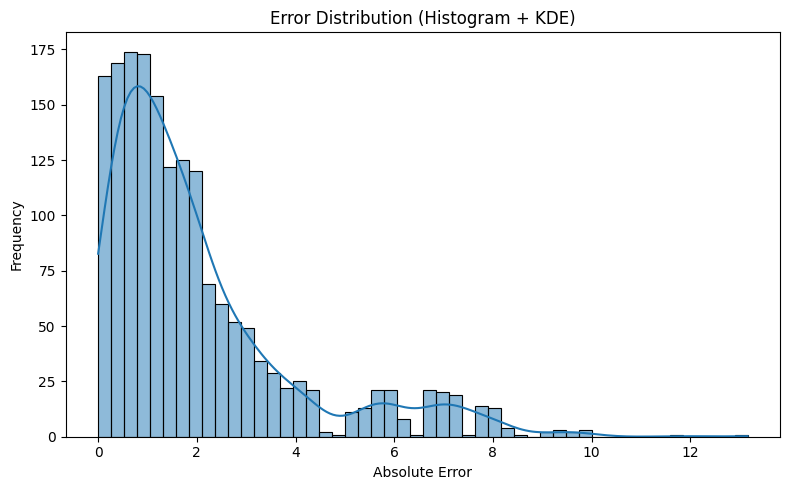

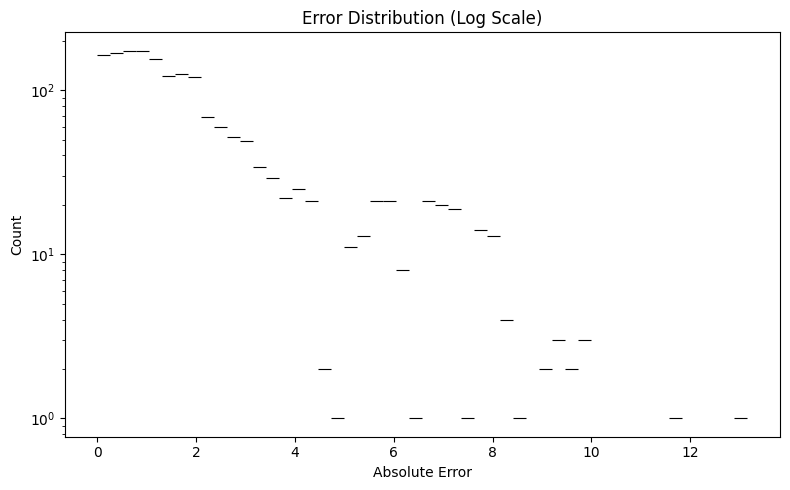

MAE    : 2.0067272
RMSE   : 2.801492
Max Err: 13.158348
Median : 1.3706207


In [38]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE : {rmse:.4f} %")
print(f"MAE  : {mae:.4f} %")
print(f"R²   : {r2:.6f}")

output_figure = os.path.join(work_dir, "figures", "gru")
os.makedirs(output_figure, exist_ok=True)
residuals = y_test - y_pred

# 1 ── True vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("True SoH")
plt.ylabel("Predicted SoH")
plt.title("Prediction vs Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig1_true_vs_pred.png"))
plt.show()

# 2 ── Residual plot
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color="r")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig2_residuals.png"))
plt.show()

# 3 ── Residual distribution
plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residual Distribution")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig3_residual_dist.png"))
plt.show()

# 4 ── Error vs SoH
plt.figure(figsize=(6, 4))
plt.scatter(y_test, np.abs(residuals), alpha=0.3)
plt.xlabel("True SoH")
plt.ylabel("Absolute Error")
plt.title("Error vs SoH")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig4_error_vs_soh.png"))
plt.show()

# 5 ── Sorted prediction
idx = np.argsort(y_test)
plt.figure(figsize=(8, 4))
plt.plot(y_test[idx], label="True")
plt.plot(y_pred[idx], label="Predicted", alpha=0.6)
plt.legend()
plt.title("Sorted SoH Prediction")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig5_sorted_pred.png"))
plt.show()

# 6 ── Training curve
plt.figure(figsize=(6, 4))
plt.plot(train_losses, label="Train RMSE")
plt.plot(val_losses, label="Val RMSE")
plt.legend()
plt.title(f"Training Curve ({'gru'})")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid()
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig6_train_curve.png"))
plt.show()

# 7 ── Violin + box
plt.figure(figsize=(8, 5))
sns.violinplot(x=np.abs(residuals), inner="quartile")
sns.boxplot(x=np.abs(residuals), width=0.2, color="white")
plt.title("Error Distribution (Violin + Box)")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig7_violin_box.png"))
plt.show()

# 8 ── CDF
errors = np.abs(residuals)
sorted_err = np.sort(errors)
cdf = np.arange(len(errors)) / len(errors)
plt.figure()
plt.plot(sorted_err, cdf)
plt.xlabel("Absolute Error")
plt.ylabel("CDF")
plt.title("Error CDF")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig8_cdf.png"))
plt.show()

# 9 ── Histogram + KDE
plt.figure(figsize=(8, 5))
sns.histplot(np.abs(residuals), bins=50, kde=True)
plt.title("Error Distribution (Histogram + KDE)")
plt.xlabel("Absolute Error")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig9_histogram.png"))
plt.show()

# 10 ── Log-scale
plt.figure(figsize=(8, 5))
sns.histplot(np.abs(residuals), bins=50, log_scale=(False, True))
plt.title("Error Distribution (Log Scale)")
plt.xlabel("Absolute Error")
plt.tight_layout()
plt.savefig(os.path.join(output_figure, "Fig10_logscale.png"))
plt.show()

print("MAE    :", np.mean(np.abs(residuals)))
print("RMSE   :", np.sqrt(np.mean(residuals**2)))
print("Max Err:", np.max(np.abs(residuals)))
print("Median :", np.median(np.abs(residuals)))


## Save Model

In [39]:
model_dir = os.path.join(work_dir, "model")
os.makedirs(model_dir, exist_ok=True)
joblib.dump(model, os.path.join(model_dir, f"{'gru'}.pkl"))
print(f"Model saved → {model_dir}/{'gru'}.pkl")


Model saved → /content/model/gru.pkl
